# 7. How the confusion matrices changed over time

Every production milestone was evaluated on the **same 50 folds** (`cv_seed` 2026; one fold signature, `88aa4f94dcce5cca`),
so their out-of-fold predictions can be compared cell by cell. This notebook reads only the saved run folders in `results/`;
nothing is retrained. The last Task 1 milestone (upload 10's rule) is applied to production's saved out-of-fold predictions
with the instagram scores traced in experiment 098 on the same folds. Counts are **flows per repeat**: each of the 10 repeats predicts every one of the 330 labelled flows once,
so a cell value of 2.5 means 2.5 of 330 flows on average.

| Date | Task 1 milestone | Task 2 milestone |
|---|---|---|
| 30 Sep | random forest baseline (006); SoftVote ensemble (004/006) | random forest baseline; SoftVote; timing dropped (007) |
| 30 Sep | 022: + first-5-packet columns, keep-facebook rule | 014: facebook/instagram specialist (**current**) |
| 1 Oct | 028: two clerks (opening expert) | |
| 1 Oct | 034: Meta gate | |
| 9 Oct | 084: pair verifiers | |
| 10 Oct | 089: rest-of-flow expert + rules | |
| 12 Oct | 100: cross-task rescue (**production model**) | |
| 21 Oct | 127: count rule of upload 10 (099 rule D on 100: instagram count raised to the training mix) | |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "official").exists())
APPS = ["facebook", "google", "instagram", "mozilla", "x", "youtube"]
INK, MUTED, OTHER = "#1f2937", "#6b7280", "#b9b8b1"
APP_COLOR = {"facebook": "#2a78d6", "instagram": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d1d5db",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})
MILESTONES = {
    "task1_static": [("30 Sep", "RF baseline", "20260930T161116Z_006_rf_baseline"),
                     ("30 Sep", "SoftVote", "20260930T161714Z_006_softvote"),
                     ("30 Sep", "022 + opening cols", "20260930T215907Z_022_blend_keep_fb"),
                     ("1 Oct", "028 two clerks", "20261001T163334Z_028_two_clerks_avg_meta_whole"),
                     ("1 Oct", "034 Meta gate", "20261001T173854Z_034_meta_gate"),
                     ("9 Oct", "084 verifiers", "20261009T220447Z_084_ALL"),
                     ("10 Oct", "089 bundle", "20261010T004051Z_089_production_check_s2026"),
                     ("12 Oct", "100 rescue (production)", "20261012T154049Z_100_production_check_s2026"),
                     ("21 Oct", "127 count rule (upload 10)", "RULE_D")],
    "task2_realtime_prefix5": [("30 Sep", "RF baseline", "20260930T161116Z_006_rf_baseline"),
                               ("30 Sep", "SoftVote", "20260930T161714Z_006_softvote"),
                               ("30 Sep", "007 no timing", "20260930T170446Z_007_t2_drop_timing5"),
                               ("30 Sep", "014 specialist (now)", "20260930T173836Z_014_fi_same_nocw")]}


def rule_d(task, base="20261012T154049Z_100_production_check_s2026"):
    """Upload 10's rule (experiment 099 rule D, file 127) applied to production's out-of-fold predictions on the same folds: in each
    held-out fold, raise the instagram count to round(fold size x the training fold's instagram share) by switching the flows not
    called instagram with the highest instagram score (099's three-expert mean, traced in 098 on these folds)."""
    o = pd.read_csv(ROOT / "results" / base / task / "oof.csv")
    tr = pd.read_csv(ROOT / "experiments/098_evidence/trace_all.csv")
    tr["s_ig"] = (tr.pw_ig + tr.po_ig + tr.pr_ig) / 3
    o = o.merge(tr[["fold", "flow_id", "s_ig"]], on=["fold", "flow_id"], how="left")
    assert o.s_ig.notna().all()
    n_all, ig_all = 330, int((o[o.fold < 5].y_true == "instagram").sum())     # one repeat holds every labelled flow once
    macro = []
    for f, g in o.groupby("fold"):
        E = int(round(len(g) * (ig_all - (g.y_true == "instagram").sum()) / (n_all - len(g))))   # training fold's share
        k = max(0, E - int((g.y_pred == "instagram").sum()))
        o.loc[g[g.y_pred != "instagram"].nlargest(k, "s_ig").index, "y_pred"] = "instagram"
        g = o.loc[g.index]
        macro.append(f1_score(g.y_true, g.y_pred, labels=sorted(o.y_true.unique()), average="macro", zero_division=0))
    return o, float(np.mean(macro))


def load(task, run):
    if run == "RULE_D":
        return rule_d(task)
    o = pd.read_csv(ROOT / "results" / run / task / "oof.csv")
    folds = pd.read_csv(ROOT / "results" / run / task / "folds.csv")
    return o, folds.macro_f1.mean()


rows, CM = [], {}
for task, ms in MILESTONES.items():
    for date, name, run in ms:
        o, macro = load(task, run)
        cm = confusion_matrix(o.y_true, o.y_pred, labels=APPS) / 10
        CM[(task, name)] = cm
        f1 = f1_score(o.y_true, o.y_pred, labels=APPS, average=None, zero_division=0)
        i = {a: APPS.index(a) for a in APPS}
        rows.append({"task": task, "date": date, "milestone": name, "macro F1": round(macro, 3),
                     "wrong per repeat": round(cm.sum() - np.trace(cm), 1),
                     **{f"{a} F1": round(float(v), 2) for a, v in zip(APPS, f1)},
                     "fb→ig": cm[i["facebook"], i["instagram"]], "ig→fb": cm[i["instagram"], i["facebook"]],
                     "fb→non-Meta": cm[i["facebook"]].sum() - cm[i["facebook"], i["facebook"]] - cm[i["facebook"], i["instagram"]],
                     "non-Meta→fb": cm[:, i["facebook"]].sum() - cm[i["facebook"], i["facebook"]] - cm[i["instagram"], i["facebook"]],
                     "yt→google": cm[i["youtube"], i["google"]], "google→yt": cm[i["google"], i["youtube"]]})
T = pd.DataFrame(rows)
T

def spread(values, gap):
    """y positions for end-of-line labels, at least `gap` apart, kept near their lines."""
    order = np.argsort(values)
    pos = np.array(values, float)[order]
    for k in range(1, len(pos)):
        pos[k] = max(pos[k], pos[k - 1] + gap)
    out = np.empty(len(pos))
    out[order] = pos
    return out


## 1. Per-app F1 at each milestone

Facebook (blue) and instagram (orange) are highlighted; the four other apps are grey.

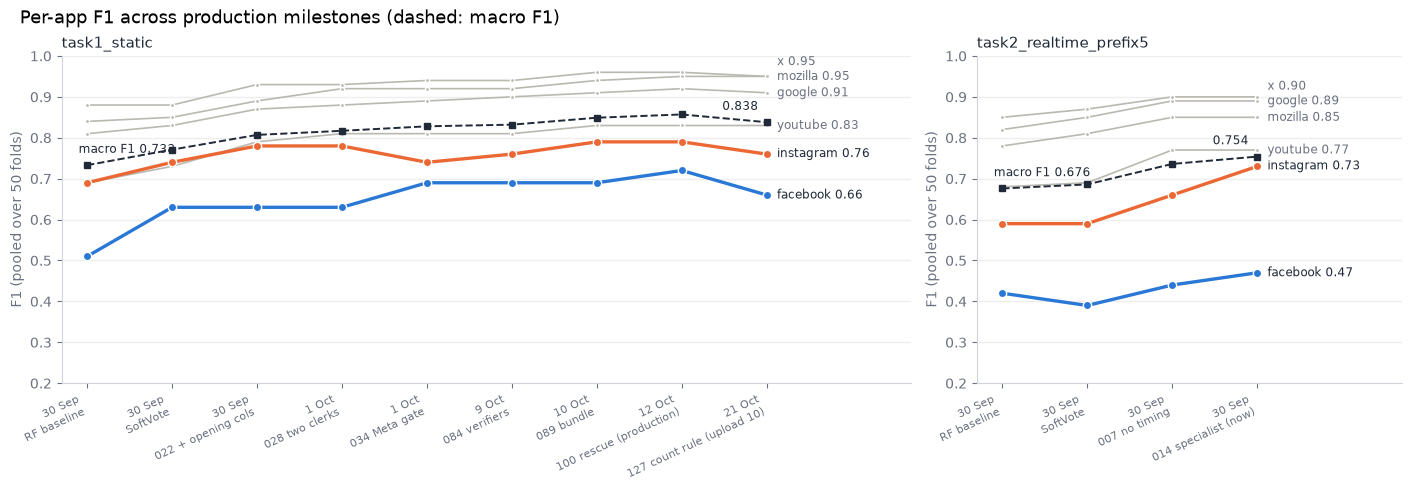

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [8, 4]}, constrained_layout=True)
for ax, task in zip(axes, MILESTONES):
    d = T[T.task == task].reset_index(drop=True)
    x = np.arange(len(d))
    ys = spread([d[f"{a} F1"].iloc[-1] for a in APPS], 0.035)
    for a, yl in zip(APPS, ys):
        col, lw, z = APP_COLOR.get(a, OTHER), 2.4 if a in APP_COLOR else 1.2, 3 if a in APP_COLOR else 1
        ax.plot(x, d[f"{a} F1"], color=col, lw=lw, marker="o", ms=6 if a in APP_COLOR else 3, zorder=z,
                markeredgecolor="white", markeredgewidth=1)
        ax.text(x[-1] + 0.12, yl, f"{a} {d[f'{a} F1'].iloc[-1]:.2f}", va="center", fontsize=8.5,
                color=INK if a in APP_COLOR else MUTED)
    ax.plot(x, d["macro F1"], color=INK, lw=1.4, ls="--", marker="s", ms=4)
    ax.text(x[0] - 0.1, d["macro F1"].iloc[0] + 0.03, f"macro F1 {d['macro F1'].iloc[0]:.3f}", fontsize=8.5, color=INK, ha="left")
    ax.text(x[-1] - 0.1, d["macro F1"].iloc[-1] + 0.03, f"{d['macro F1'].iloc[-1]:.3f}", fontsize=8.5, color=INK, ha="right")
    ax.set_xticks(x, [f"{dt}\n{m}" for dt, m in zip(d.date, d.milestone)], fontsize=8, rotation=25, ha="right")
    ax.set_xlim(-0.3, len(d) - 0.3 + 1.0)
    ax.set_ylim(0.2, 1.0)
    ax.set_ylabel("F1 (pooled over 50 folds)")
    ax.set_title(task, loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", color="#eeeeec", lw=1)
    ax.set_axisbelow(True)
fig.suptitle("Per-app F1 across production milestones (dashed: macro F1)", x=0.01, ha="left", fontsize=13)
plt.show()

## 2. The Meta and google/youtube confusion cells at each milestone

Wrong flows per repeat (out of 330), Task 1, for the cells the milestones targeted.

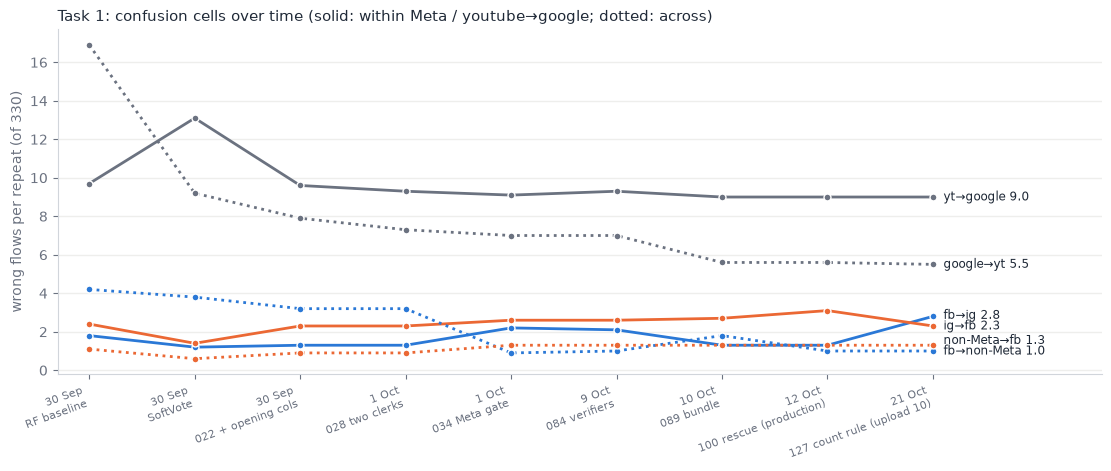

In [3]:
d = T[T.task == "task1_static"].reset_index(drop=True)
cells_ = [("fb→ig", "#2a78d6", "-"), ("ig→fb", "#eb6834", "-"), ("fb→non-Meta", "#2a78d6", ":"),
          ("non-Meta→fb", "#eb6834", ":"), ("yt→google", MUTED, "-"), ("google→yt", MUTED, ":")]
fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
x = np.arange(len(d))
ys = spread([d[name].iloc[-1] for name, _, _ in cells_], 0.55)
for (name, col, ls), yl in zip(cells_, ys):
    ax.plot(x, d[name], color=col, ls=ls, lw=2, marker="o", ms=5, markeredgecolor="white")
    ax.text(x[-1] + 0.1, yl, f"{name} {d[name].iloc[-1]:.1f}", va="center", fontsize=8.5, color=INK)
ax.set_xticks(x, [f"{dt}\n{m}" for dt, m in zip(d.date, d.milestone)], fontsize=8, rotation=20, ha="right")
ax.set_xlim(-0.3, len(d) + 0.6)
ax.set_ylabel("wrong flows per repeat (of 330)")
ax.set_title("Task 1: confusion cells over time (solid: within Meta / youtube→google; dotted: across)", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color="#eeeeec", lw=1)
ax.set_axisbelow(True)
plt.show()

## 3. What changed between the first and the current model

Each cell shows the change in flows per repeat (current minus the random-forest baseline). The **colour shows whether that
change is good**: **blue = better** (more correct flows on the diagonal, fewer mistakes off it), **red = worse**.

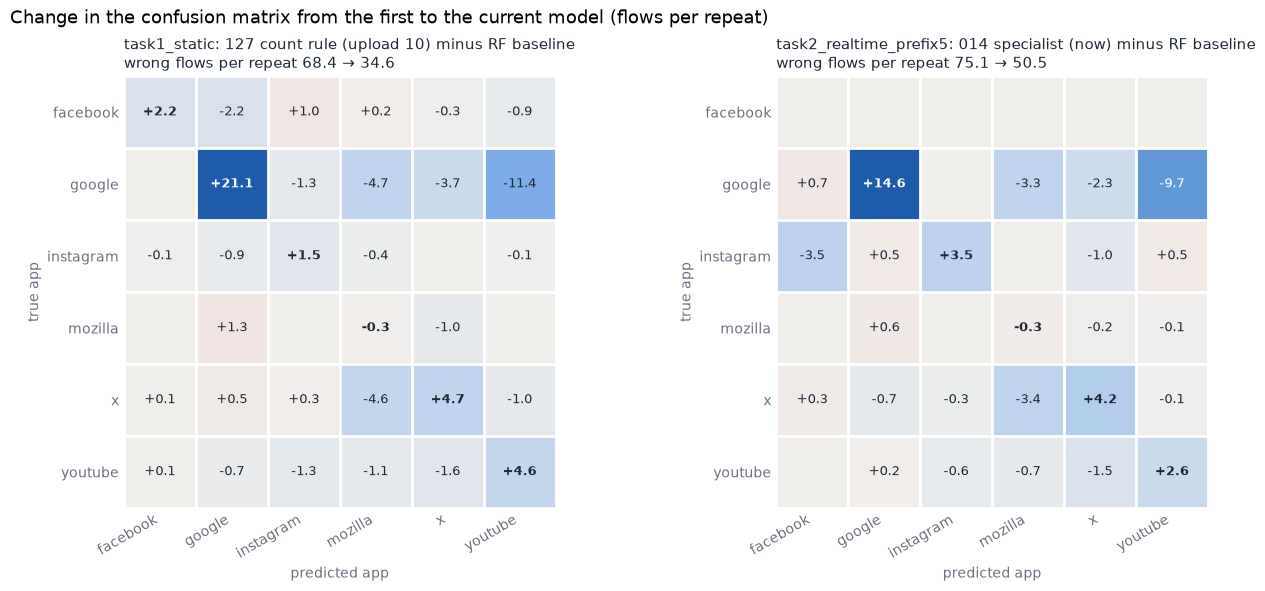

In [4]:
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f2a0a0", "#c62828"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), constrained_layout=True)
for ax, task in zip(axes, MILESTONES):
    first, last = MILESTONES[task][0][1], MILESTONES[task][-1][1]
    D = CM[(task, last)] - CM[(task, first)]
    G = np.where(np.eye(6, dtype=bool), D, -D)   # goodness: + = better (more correct, fewer mistakes)
    lim = np.abs(G).max()
    ax.imshow(-G, cmap=DIV, vmin=-lim, vmax=lim)
    for i in range(6):
        for j in range(6):
            if abs(D[i, j]) >= 0.05:
                ax.text(j, i, f"{D[i, j]:+.1f}", ha="center", va="center", fontsize=9,
                        fontweight="bold" if i == j else "normal", color="white" if abs(G[i, j]) > 0.6 * lim else INK)
    ax.set_xticks(np.arange(-0.5, 6), minor=True)
    ax.set_yticks(np.arange(-0.5, 6), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(6), APPS, rotation=30, ha="right")
    ax.set_yticks(range(6), APPS)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel("predicted app")
    ax.set_ylabel("true app")
    wrong0, wrong1 = CM[(task, first)].sum() - np.trace(CM[(task, first)]), CM[(task, last)].sum() - np.trace(CM[(task, last)])
    ax.set_title(f"{task}: {last} minus {first}\nwrong flows per repeat {wrong0:.1f} → {wrong1:.1f}", loc="left", fontsize=11, color=INK)
fig.suptitle("Change in the confusion matrix from the first to the current model (flows per repeat)", x=0.01, ha="left", fontsize=13)
plt.show()

## Summary

1. **Errors halved in Task 1** (68.4 → 32.7 wrong flows per repeat; macro F1 0.733 → 0.857) and fell by a third in Task 2
   (75.1 → 50.5; 0.676 → 0.754). The production model has not changed since 12 October; the experiments since (101-126) were
   measured but not adopted.
2. **Most of the gain is google.** Google flows called youtube fell from 16.9 to 5.6 per repeat in Task 1 (17.7 → 8.0 in Task 2),
   and correct google predictions rose by 21.7 (14.6). The opposite cell, **youtube called google, never moved** (about 9 in Task 1,
   about 11 in Task 2, at every milestone).
3. **Facebook improved in Task 1 by stopping it leaking to other apps**: facebook flows called a non-Meta app fell from 4.2 to 1.0
   (the 034 gate and the 100 rescue), and facebook F1 rose 0.51 → 0.72. The price is **instagram called facebook**, which rose
   from 2.4 to 3.1; instagram F1 has been flat at about 0.79 since 022, after a dip at the 034 gate (0.74) that 087/089 repaired.
4. **In Task 2 the facebook/instagram collision never moved.** Facebook called instagram is 5.0 per repeat at every milestone; the
   014 specialist only cut the reverse error (instagram called facebook, 6.2 → 2.7), which lifted instagram F1 0.59 → 0.73 while
   facebook F1 stayed below 0.5.
5. **What is left** is the two cells no milestone touched: youtube called google, and facebook called instagram in Task 2. Both are
   the identical-opening collisions measured in 115 and 117.
6. **Upload 10's count rule (21 October) is worse in cross-validation but scored best on the test set.** On these folds it lowers
   Task 1 macro F1 from 0.857 to 0.838 (wrong flows per repeat 32.7 → 34.6; facebook F1 0.72 → 0.66, instagram 0.79 → 0.76): it
   trades instagram called facebook (3.1 → 2.3) for more facebook called instagram (1.3 → 2.8). On the test set the same rule took
   Task 1 from 0.822 (upload 8) to 0.912 (90.85 total). The test set's instagram shortfall was outside the cross-validation range
   (099), which is where a count correction pays off; it is one result on three flows, not evidence that the rule works in general.
